# Motoneuron pool simulation

This notebook simulates a pool of motoneurons driven by excitatory and inhibitory input, with neuromodulation that varies from cell to cell. It computes firing rates, works out when each unit is recruited and derecruited, and compares the result against motor units recorded experimentally.

**What it covers**
- A two-compartment biophysical motoneuron model (Na⁺, K⁺ and Ca²⁺ channels)
- Several shapes of excitatory drive (triangular, trapezoidal, sinusoidal, chirp)
- Recruitment thresholds and hysteresis, the signature of the persistent inward current (PIC)
- A comparison against experimentally measured hysteresis
- Spike rasters, firing-rate traces and state-space plots

The notebook runs top to bottom. Sections 1–4 build the model, Section 5 runs it, and Sections 6–11 analyse what comes out.

---

## 1. Environment setup

### 1.1 Package imports

In [1]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict
using Statistics

# Data handling
using JLD2, MAT, CSV, DataFrames

# Numerical / signal processing
using DSP

# Visualization
using Plots, CairoMakie, Makie
using Colors, ColorSchemes


println("✓ Packages loaded")

┌ Warning: Package Polynomials does not have MakieCore in its dependencies:
│ - If you have Polynomials checked out for development and have
│   added MakieCore as a dependency but haven't updated your primary
│   environment's manifest file, try `Pkg.resolve()`.
│ - Otherwise you may need to report an issue with Polynomials
└ Loading MakieCore into Polynomials from project dependency, future warnings for Polynomials are suppressed.


✓ Packages loaded


In [2]:
# ---- Global figure style (Arial, larger fonts) — applies to EVERY plot below ----
using Plots.PlotMeasures

Plots.default(
    fontfamily        = "Arial",
    titlefontsize     = 15,
    guidefontsize     = 14,     # axis labels
    tickfontsize      = 12,     # tick numbers
    legendfontsize    = 11,
    linewidth         = 3,
    markersize        = 6,
    markerstrokewidth = 0,
    grid              = false,
    left_margin       = 4mm,
    bottom_margin     = 4mm,
)

println("✓ Figure style set (Arial, larger fonts). Applies to all plots in this notebook.")

✓ Figure style set (Arial, larger fonts). Applies to all plots in this notebook.


### 1.2 Load the model functions

The model itself lives in `utils/functions_run_simulations`. Every `.jl` file in that folder is included below.

In [3]:
# Path to the model functions — change this to wherever you cloned the repository
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_run_simulations"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Functions directory not found. Please update folder_path variable.")
end

✓ Loaded: calculate_rates_with_timebase.jl
✓ Loaded: conv_spikes_rates.jl
✓ Loaded: creation_model.jl
✓ Loaded: creation_model_controller.jl
✓ Loaded: filter_input.jl
✓ Loaded: plot_MN_trajectory.jl
✓ Loaded: plot_spike_raster.jl
✓ Loaded: run_from_manifest.jl
✓ Loaded: run_sim.jl
✓ Loaded: run_sim_noise.jl
✓ Loaded: run_sim_onemn.jl


---

## 2. Model parameters

### 2.1 Load the fitted calcium thresholds

Each motoneuron has its own calcium activation threshold, `VthCa`. These were fitted unit by unit so that the model reproduces the recruitment hysteresis measured in real motor units — Section 11 shows how that fit works for a single cell. The file loaded here holds the fitted values for one subject, and its length sets the size of the pool.

In [4]:
# Fitted calcium activation thresholds for one subject
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2" VthCa_newTA

nr_s = size(VthCa_newTA, 2)  # one threshold per motoneuron, so this sets the pool size

println("✓ Loaded optimized VthCa data")
println("Number of motoneurons: ", nr_s)

✓ Loaded optimized VthCa data
Number of motoneurons: 181


### 2.2 Morphology

The pool spans a range of cell sizes, which is what makes small motoneurons recruit before large ones. Every parameter below is swept linearly from the smallest cell in the pool to the largest.

- **Rheobase** 3.5–6.5 nA — the current a cell needs before it fires
- **Soma radius** 38.75–41.25 μm
- **Soma length** 77.5–82.5 μm
- **Dendrite radius** 20.75–31.25 μm
- **Dendrite length** 5500–6800 μm

In [5]:
# Rheobase, with a little scatter so no two cells come out identical
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)  # nA

# Soma dimensions, converted to cm
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000  # cm
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000    # cm
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000    # Ω⋅cm

# Dendrite dimensions, converted to cm
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000   # cm
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000 # cm
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000    # Ω⋅cm

println("✓ Morphological parameters defined")

✓ Morphological parameters defined


### 2.3 Ion channel conductances

Maximum conductance of each channel type, in mS/cm². These set how strong each ionic current can get.

- **gNa** — fast sodium, the upstroke of the action potential
- **gKf** — fast potassium, repolarisation
- **gKs** — slow potassium, spike-frequency adaptation
- **gCa** — dendritic calcium, the persistent inward current (PIC)

In [6]:
# Maximum conductances (mS/cm²)
max_gna = 30.0                          # Sodium
max_gkf_S = ones(nr_s) .* 4.0          # Fast potassium
max_gks_S = LinRange(16, 25, nr_s)     # Slow potassium
max_gca_S = LinRange(0.038, 0.029, nr_s)  # Calcium

println("✓ Ion channel conductances defined")

✓ Ion channel conductances defined


### 2.4 Channel kinetics

Rate constants, in ms⁻¹, setting how fast each channel opens and closes.

- **m, h** — sodium activation and inactivation
- **n** — fast potassium activation
- **q** — slow potassium activation
- **p** — dendritic calcium activation

In [7]:
# Sodium channel kinetics (ms⁻¹)
αm = ones(nr_s) .* 22.0
βm = ones(nr_s) .* 13.0
αh_S = ones(nr_s) .* 0.5
βh_S = ones(nr_s) .* 4.0

# Potassium channel kinetics (ms⁻¹)
αn_S = ones(nr_s) .* 1.5
βn_S = ones(nr_s) .* 0.1
αq_S = ones(nr_s) .* 1.5
βq_S = LinRange(0.025, 0.038, nr_s)

# Calcium channel kinetics (ms⁻¹)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

# Calcium activation threshold, one value per unit, from the fitted file loaded in 2.1.
# Uncomment the line below instead to give the whole pool a uniform threshold.
Vthca_S = VthCa_newTA[1, :]
# Vthca_S = LinRange(2.5, 3, nr_s)


println("✓ Gating kinetics defined")

✓ Gating kinetics defined


### 2.5 Force parameters

The twitch each motor unit produces, used to turn spike trains into force.

- **Apeak** — peak twitch force
- **tpeak** — time to peak
- **tetanic** — tetanic scaling factor

In [8]:
# Force parameters
Apeak_S = LinRange(0.103, 0.123, nr_s)
tpeak_S = LinRange(110.0, 100.0, nr_s)
tetanic_S = LinRange(0.393, 0.491, nr_s)

println("✓ Force parameters defined")

✓ Force parameters defined


### 2.6 Neuromodulation

Neuromodulatory drive amplifies the persistent inward current, and how much amplification a unit gets is what decides how much hysteresis it shows. `γa` and `γh` set that gain; `IF` sets how much inhibition each unit receives.

In [9]:
# Neuromodulatory amplification
γa = 1.0
γh = ones(nr_s)

# Per-unit inhibition: IF runs from 1 for the unit with the lowest calcium threshold
# down to 0 for the unit with the highest, so the earliest-activating PICs get the most inhibition
IF = zeros(nr_s)
max_val = maximum(VthCa_newTA[1, :])
min_val = minimum(VthCa_newTA[1, :])

for i in 1:length(VthCa_newTA[1, :])
    IF[i] = 1.0 - (VthCa_newTA[1, i] - min_val) / (max_val - min_val)
end

# Uncomment for the same inhibition across the whole pool
# IF = LinRange(1.0, 1.0, nr_s)

println("✓ Neuromodulation parameters defined")

✓ Neuromodulation parameters defined


### 2.7 Reversal potentials and synaptic parameters

These potentials are centred on 0 mV rather than on the resting potential, which keeps the equations tidy. Subtract 65 mV to read them as physiological values.

In [10]:
# Reversal potentials (mV, centered at 0)
EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16

# Synaptic conductances
Ge = 0.6; Gi = 0.5

# Initial voltages
Vd0 = 0.0; Vs0 = 0.0

# Refractory period and pulse duration
rp = 5.0
pd = 1.0

println("✓ Electrical parameters defined")

✓ Electrical parameters defined


---

## 3. Input to the pool

### 3.1 Excitatory drive

The pool is driven by a slow triangular ramp. Taking the drive up and then back down is what lets us measure recruitment on the way up and derecruitment on the way down, and so quantify hysteresis in Section 8. Other drive shapes are available in Section 3.2.

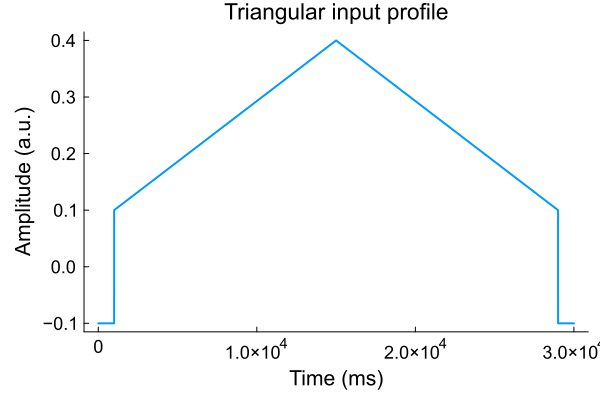

In [36]:
# Triangular excitatory drive: a slow ramp up and back down again
amplitude = 0.4
tr_length = 28000
sim_length = 30000

half_triang = div(tr_length, 2)
flat_line = fill(-0.1, 1000)
up = range(0.1, amplitude, length=half_triang + 1)
down = range(amplitude, 0.1, length=tr_length - half_triang + 1)
input = vcat(flat_line, up[2:end], down[2:end], flat_line)

Plots.plot(input, xlabel="Time (ms)", ylabel="Amplitude (a.u.)",
           title="Triangular input profile", legend=false, linewidth=2)

### 3.2 Other drive shapes (optional)

Trapezoidal, sinusoidal and chirp profiles. Uncomment one block to use it in place of the triangular ramp.

In [12]:
# === TRAPEZOIDAL ===
# flat_length = 20000
# remaining_length = sim_length - flat_length
# edge_length = div(remaining_length, 2)
# flat = fill(amplitude, flat_length)
# up = range(0, amplitude, length=edge_length + 1)
# down = range(amplitude, 0, length=edge_length + 1)
# input = vcat(up[2:end], flat, down[2:end])

In [13]:
# === SINUSOIDAL ===
# sim_length = 5000
# frequency = 0.25  # Hz
# amplitude_min = 0.16
# amplitude_max = 0.4
# duration = 5.0
# t = range(0, stop=duration, length=sim_length)
# phase = 2π .* frequency .* t .- π/2
# signal = sin.(phase)
# signal = (signal .+ 1) ./ 2
# input = signal .* (amplitude_max - amplitude_min) .+ amplitude_min

In [14]:
# === CHIRP ===
# sim_length = 10000
# duration = 10.0
# f0 = 0.0; f1 = 3.0
# amplitude_min = 0.25; amplitude_max = 1.0
# t = range(0, stop=duration, length=sim_length)
# phase = 2π .* (f0 .* t .+ 0.5 .* (f1 - f0) .* (t.^2 ./ duration))
# signal = sin.(phase .- π/2)
# signal = (signal .+ 1) ./ 2
# input = signal .* (amplitude_max - amplitude_min) .+ amplitude_min

### 3.3 Derive each motoneuron's electrical properties

Morphology fixes electrical behaviour, so this step turns the sizes defined above into conductances, capacitances and thresholds, then collects everything into one dictionary per motoneuron.

- **gls, gld** — leak conductance of soma and dendrite
- **gc** — coupling between the two compartments
- **rn** — input resistance
- **Vth** — spiking threshold
- **cs, cd** — membrane capacitance
- **gNa, gKf, gKs, gCa** — channel conductances, converted from density to absolute values

In [15]:
# Constants
ri = 70.0  # Intracellular resistivity
cm = 1.0   # Membrane capacitance

# Preallocate arrays
MN_list = []
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s)
gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s)
gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s)
cs_S = zeros(nr_s); cd_S = zeros(nr_s)

# Compute for each motoneuron
for i in 1:nr_s
    # Leak conductances (μS)
    gls_S[i] = ((2π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    
    # Coupling conductance (μS)
    gc_S[i] = (2 / ((ri * ld_S[i] / (π * rd_S[i]^2)) + 
                    (ri * ls_S[i] / (π * rs_S[i]^2)))) * 1e6
    
    # Input resistance (MΩ)
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    
    # Voltage threshold (mV)
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    
    # Capacitances (nF)
    cs_S[i] = 2π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances (μS)
    gna_S[i] = 2π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Everything this motoneuron needs, in one dictionary
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],:gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],:gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],:βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],:VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i], :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],"type" => "All Type")
    
    push!(MN_list, S_MN)
end

MNs = MN_list

println("✓ Computed properties for ", nr_s, " motoneurons")


✓ Computed properties for 181 motoneurons


### 3.4 Does cell size explain the fitted PIC?

If the fitted calcium threshold were simply a consequence of how big a cell is, it would fall on a single curve against calcium conductance (`gCa`, which scales with dendrite area). Here the two are plotted against each other for all eight subjects. The spread at any given `gCa` is wide, which says size alone does not account for how much PIC a unit carries.

Markers are individual motoneurons, lines are least-squares polynomial fits (cubic where at least 30 units were fitted, linear otherwise), and the text gives Spearman's ρ with its p-value.

  S1: n= 59  deg=3  rho=-0.41  p=0.0013  F(cubic vs quad) p=0.018
  S2: n=158  deg=3  rho=-0.55  p=0.0000  F(cubic vs quad) p=0.001
  S3: n= 58  deg=3  rho=-0.78  p=0.0000  F(cubic vs quad) p=0.006
  S4: n=100  deg=3  rho=-0.58  p=0.0000  F(cubic vs quad) p=0.112
  S5: n= 50  deg=3  rho=-0.50  p=0.0002  F(cubic vs quad) p=0.050
  S6: n= 62  deg=3  rho=+0.20  p=0.1114  F(cubic vs quad) p=0.003
  S7: n= 16  deg=1  rho=-0.40  p=0.1278  F(cubic vs quad) p=NaN
  S8: n= 48  deg=3  rho=-0.52  p=0.0002  F(cubic vs quad) p=0.100


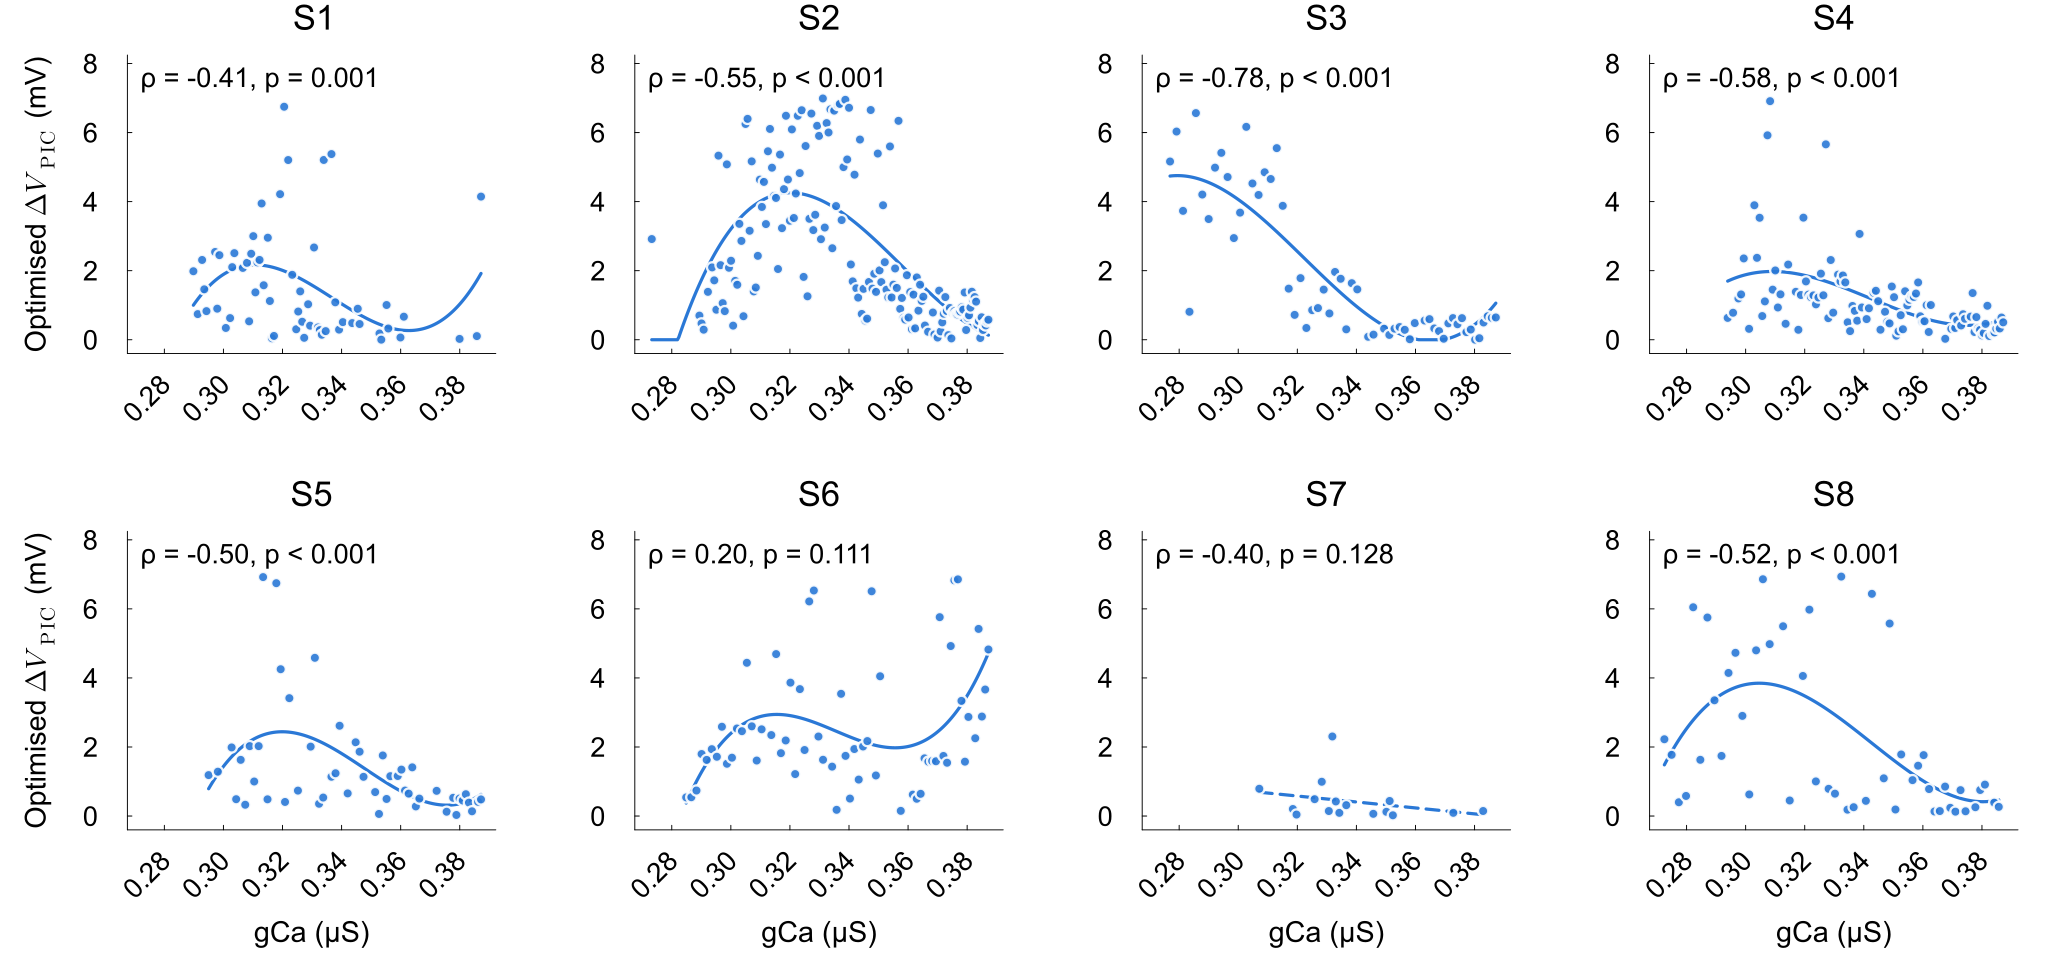

In [16]:
using JLD2, Plots, Statistics, StatsBase, Distributions, Printf, LinearAlgebra

vthca_gca_grid = let
    DIR     = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process"
    BLUE    = RGB(42/255, 120/255, 214/255)
    FS      = 19          # one knob for every font size in the figure
    MIN_CUB = 30          # below this many points a cubic overfits -> stay linear

    # least squares polynomial fit
    polyfit(x, y, deg) = reduce(hcat, [x .^ d for d in 0:deg]) \ y
    polyval(c, x)      = sum(c[d + 1] .* x .^ d for d in 0:(length(c) - 1))

    res = NamedTuple[]
    for s in 1:8
        f = joinpath(DIR, "VthCa_TA_subject$(s)_gamma1.jld2")
        isfile(f) || continue
        local VthCa_newTA
        JLD2.@load f VthCa_newTA
        v = vec(VthCa_newTA); N = length(v)
        opt = findall(!=(0.0), v); n = length(opt)
        n < 4 && continue

        rd  = LinRange(20.75, 31.25, N) ./ 10000
        ld  = LinRange(5500.0, 6800.0, N) ./ 10000
        mgc = LinRange(0.038, 0.029, N)
        gca = [2π * ld[i] * rd[i] * mgc[i] * 1e3 for i in 1:N]

        x, y = gca[opt], v[opt]
        rho  = corspearman(x, y)                 # rank-based: assumes no functional form
        tt   = rho * sqrt((n - 2) / (1 - rho^2))
        p    = 2 * ccdf(TDist(n - 2), abs(tt))

        deg = n >= MIN_CUB ? 3 : 1               # S7 (n=16) would overfit a cubic
        c   = polyfit(x, y, deg)

        # nested F-test, cubic vs quadratic: does the extra term earn its place?
        pF = NaN
        if deg == 3
            ss2 = sum((y .- polyval(polyfit(x, y, 2), x)) .^ 2)
            ss3 = sum((y .- polyval(c, x)) .^ 2)
            pF  = ccdf(FDist(1, n - 4), ((ss2 - ss3) / 1) / (ss3 / (n - 4)))
        end

        xs = range(minimum(x), maximum(x), length = 250)
        # VthCa is a threshold offset the optimiser only ever returned as >= 0,
        # so never draw the curve below zero (S2 and S3 would dip negative)
        ys = max.(polyval(c, xs), 0.0)

        push!(res, (s=s, x=x, y=y, n=n, N=N, rho=rho, p=p, pF=pF, deg=deg, xs=xs, ys=ys))
    end

    xlo = minimum(minimum(r.x) for r in res) - 0.005
    xhi = maximum(maximum(r.x) for r in res) + 0.005
    yhi = maximum(maximum(r.y) for r in res) * 1.18

    panels = Plots.Plot[]
    for (k, r) in enumerate(res)
        row = (k - 1) ÷ 4 + 1
        col = (k - 1) % 4 + 1

        pl = Plots.plot(grid = false, legend = false, fontfamily = "Arial",
                        xlims = (xlo, xhi), ylims = (-0.4, yhi),
                        title = "S$(r.s)", titlefontsize = FS + 5,
                        xticks = 0.28:0.02:0.38, yticks = 0:2:8,
                        xrotation = 45,          # rotated so more ticks fit
                        xlabel = row == 2 ? "gCa (µS)" : "",
                        ylabel = col == 1 ? L"Optimised $\Delta V_{\mathrm{PIC}}$ (mV)" : "",
                        guidefontsize = FS + 1,
                        xtickfontsize = FS, ytickfontsize = FS,
                        framestyle = :axes, foreground_color_border = :black,
                        left_margin = 7Plots.mm, bottom_margin = 7Plots.mm)

        Plots.plot!(pl, r.xs, r.ys, lw = 3.4, color = BLUE,
                    linestyle = r.deg == 3 ? :solid : :dash)
        Plots.scatter!(pl, r.x, r.y, ms = 6.0, color = BLUE,
                       markerstrokecolor = :white, markerstrokewidth = 1.2, alpha = 0.9)

        pstr = r.p < 0.001 ? "p < 0.001" : @sprintf("p = %.3f", r.p)
        Plots.annotate!(pl, xlo + 0.005, yhi * 0.97,
            Plots.text(@sprintf("ρ = %.2f, %s", r.rho, pstr), :left, :top, FS, "Arial"))
        push!(panels, pl)
    end

    plt = Plots.plot(panels..., layout = (2, 4), size = (2150, 1020),
                     top_margin = 7Plots.mm, bottom_margin = 20Plots.mm,
                     left_margin = 17Plots.mm, right_margin = 6Plots.mm)

    Plots.savefig(plt, "/Users/nmt121/Desktop/vthca_vs_gca_allsubjects.pdf")
    for r in res
        @printf("  S%d: n=%3d  deg=%d  rho=%+.2f  p=%.4f  F(cubic vs quad) p=%.3f\n",
                r.s, r.n, r.deg, r.rho, r.p, r.pF)
    end
    plt
end



### 3.5 Inhibitory drive

A constant level of inhibition, scaled to the excitatory amplitude. Alternatives follow in the next cells.

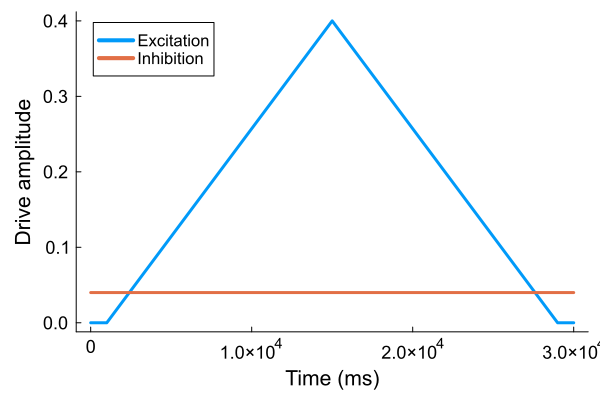

In [17]:
# Constant inhibition 
inh_factor = 0.1
inh_input = fill(inh_factor * amplitude, sim_length)

# Visualize
Plots.plot(input, label="Excitation", linewidth=3, legend=:topleft, xlabel="Time (ms)", ylabel="Drive amplitude", grid=false)
Plots.plot!(inh_input, label="Inhibition", linewidth=3)


#### Other inhibitory profiles (uncomment to use)

In [18]:
# # === INVERSELY PROPORTIONAL ===
# exc_min = minimum(input); exc_max = maximum(input)
# exc_normalized = (input .- exc_min) ./ (exc_max - exc_min)
# inh_factor = 0.9
# inh_input = exc_max .* (1.0 .- inh_factor .* exc_normalized)
# Plots.plot(input, label="Excitation", linewidth=3, legend=:topleft, xlabel="Time (ms)", ylabel="Drive amplitude", grid=false)
# Plots.plot!(inh_input, label="Inhibition", linewidth=3)


In [19]:
# # === PROPORTIONAL ===
# inh_factor = 0.9
# inh_amplitude = 0.4 * inh_factor
# half_triang = div(28000, 2)
# flat_line = fill(0, 1000)
# up = range(0, inh_amplitude, length=half_triang + 1)
# down = range(inh_amplitude, 0, length=28000 - half_triang + 1)
# inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)

---

## 4. Setting up the simulation

### 4.1 Initial conditions and storage

Every gating variable starts from rest, and one array per state variable is allocated to hold the whole pool across the whole run.

In [20]:
# Define helper function
_int(num) = floor(Int, num)

# Simulation parameters
const dt = 0.05
tspan = 0:dt:sim_length
sim_time = _int(sim_length / dt)

# Facilitation flag read by ode4 (must be defined before run_sim / run_sim_onemn)
flag = false

# Initial conditions
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

# Input arrays
full_input = zeros(nr_s, sim_length)
independantnoise = zeros(nr_s, sim_length)
commoninput = input

println("✓ Simulation initialized")
println("  Time steps: ", sim_time)
println("  Duration: ", sim_length, " ms")

✓ Simulation initialized
  Time steps: 600000
  Duration: 30000 ms


---

## 5. Running the pool

### 5.1 Get the spikes — run **or** load

- **Run from scratch** (next cell): `run_sim()` integrates the whole pool. Expect several minutes.
- **Load a saved result** (the cell after): reads a stored `spike_array` instantly.

Either way you end up with `spike_array` in memory, which is all the rest of the notebook needs. If you load, skip the run cell.

In [21]:
# println("\n" * "="^60)
# println("Starting simulation...")
# println("This may take several minutes for ", nr_s, " motoneurons.")
# println("="^60 * "\n")

# @time spike_array, vs_array, pt_arr = run_sim() #if you want to add more synaptic noise use function run_sim_noise in functions

# println("\n" * "="^60)
# println("✓ Simulation completed")
# println("="^60)
# println("\nResults:")
# println("  Total spikes: ", Int(sum(spike_array)))
# println("  Active neurons: ", sum(sum(spike_array, dims=2) .> 0), " / ", nr_s)

In [22]:
#################################
######## LOAD SIMULATION ########
#################################

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/DR_subject1_TA.jld2" spike_array 

1-element Vector{Symbol}:
 :spike_array

### 5.2 Save the results (optional)

Uncomment and set your own paths to keep the simulation output.

In [23]:
# Save to JLD2
# JLD2.@save "simulation_results.jld2" spike_array vs_array pt_arr

# Save to MAT (for MATLAB)
# MAT.matwrite("simulation_results.mat", Dict("spike_array" => spike_array,"vs_array" => vs_array))

---

## 6. Visualisation

### 6.1 Voltage traces (optional)

Somatic voltage for every motoneuron. Useful for checking the model is behaving itself, but slow to draw for a large pool.

In [24]:
# Uncomment to visualize voltage traces
# WARNING: This can be slow for large numbers of motoneurons

# fig = CairoMakie.Figure(resolution = (2000, 1000))
# rows = ceil(Int, sqrt(nr_s))
# cols = ceil(Int, nr_s / rows)
# for i in 1:nr_s
#     row = div(i - 1, cols) + 1
#     col = mod(i - 1, cols) + 1
#     ax = CairoMakie.Axis(fig[row, col])#) title = "Motoneuron $i", xlabel = "Time", ylabel = "Voltage")
#     CairoMakie.lines!(ax, vs_array[i, 1:600000], label = "Trace $i")
# end
# CairoMakie.display(fig)

### 6.2 Spike raster

Spike times for the whole pool. This is the clearest view of recruitment order: units appear in pool order, smallest to largest, so recruitment should sweep across the pool as the drive rises and unwind again as it falls.

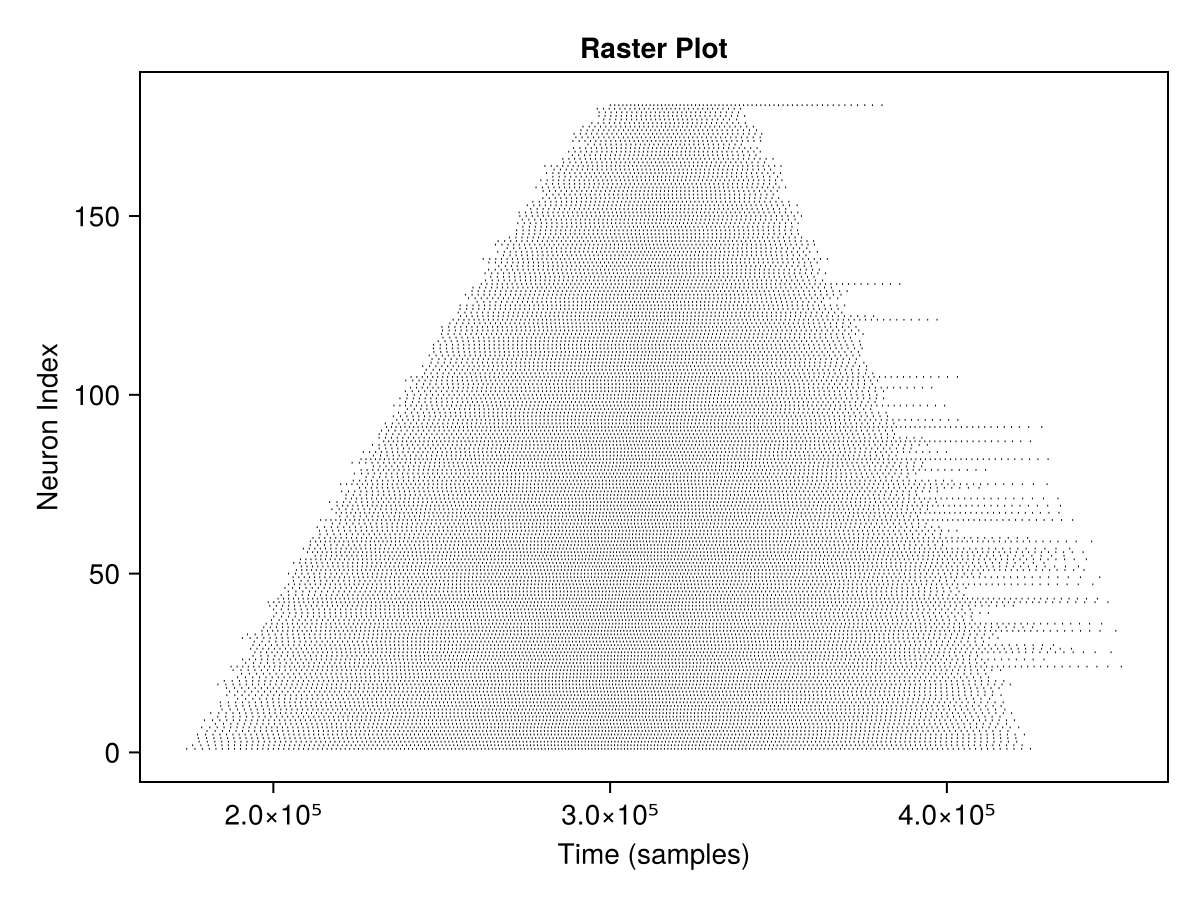

✓ Raster plot generated


In [25]:
# Create raster plot
fig = plot_spike_raster(spike_array)
CairoMakie.display(fig)

println("✓ Raster plot generated")

---

## 7. Firing rates

### 7.1 Instantaneous firing rate

Firing rate for each unit, computed from its inter-spike intervals.

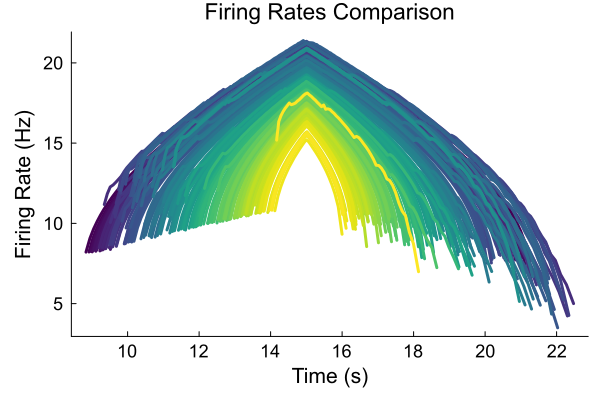

In [26]:
sampling_rate = 20000  # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

color_map = get(ColorSchemes.viridis, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], color=color_map[i], legend=false, grid=false)
    end
end

display(p)

### 7.2 Pad the rates to a common length (optional)

Units fire for different lengths of time, so their rate vectors come out with different lengths. Padding with NaN puts them all in one rectangular matrix for analyses that need it.

In [27]:
# Uncomment if needed for analysis

# num_rows = length(all_timebases)
# row_lengths = [length(row) for row in all_timebases]
# max_length = maximum(row_lengths)
# new_all_bases = zeros(nr_s, max_length)

# for i in 1:nr_s
#     rate_per_neuron = all_timebases[i]
#     padding = max_length - length(rate_per_neuron)
#     new_all_bases[i, :] .= vcat(rate_per_neuron, fill(NaN, padding))
# end

### 7.3 State-space trajectory

Firing rate of one motoneuron plotted against another. This is the view behind the online cursor-control task, where the rates of two units become the coordinates of a cursor.

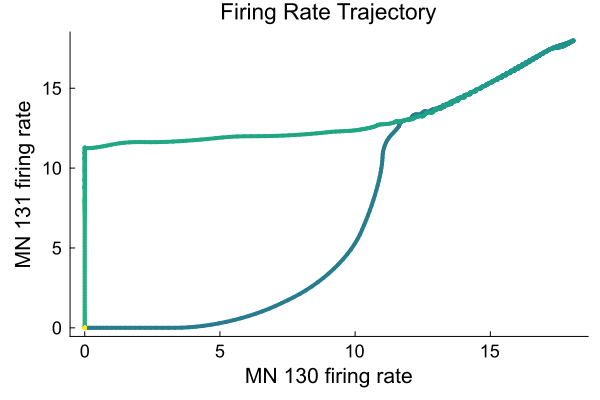

✓ Trajectory generated for neurons 130 and 131


In [28]:
# Plot trajectory for specific pair
mn1 = 130
mn2 = 131

if mn1 <= nr_s && mn2 <= nr_s
    p, avg_traj = plot_MN_trajectory(spike_array, mn1, mn2, v=100)
    display(p)
    println("✓ Trajectory generated for neurons ", mn1, " and ", mn2)
else
    println("⚠️ Selected neurons exceed pool size")
end

---

## 8. Hysteresis

### 8.1 Recruitment and derecruitment thresholds

For each unit we read off the excitatory drive at its first spike and at its last. A unit with a strong PIC keeps firing on the way down past the level that recruited it, so the two differ.

- **Recruitment threshold** — drive at the first spike
- **Derecruitment threshold** — drive at the last spike
- **Hysteresis** — derecruitment / recruitment − 1, so a negative value means the unit stayed on below the level that recruited it

In [29]:
# Read off the excitatory drive at the moment each unit starts and stops firing.
# spike_array is indexed in samples, so the ramp is rebuilt here at sample resolution.
nr_s = size(spike_array, 1)
amplitude    = 0.4
ramp_samples = 560000                        # up+down ramp length in SAMPLES (total tr = 600000)
half_triang  = div(ramp_samples, 2)
flat_line = fill(-0.1, 20000)
up   = range(-0.1, amplitude, length = half_triang + 1)
down = range(amplitude, -0.1, length = ramp_samples - half_triang + 1)
tr   = vcat(flat_line, up[2:end], down[2:end], flat_line)

recr_inter_input   = zeros(1, nr_s)
derecr_inter_input = zeros(1, nr_s)
hysteresis         = zeros(1, nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1, n]   = tr[findfirst(==(1), spike_array[n, :])]   # drive at recruitment
        derecr_inter_input[1, n] = tr[findlast(==(1),  spike_array[n, :])]   # drive at derecruitment
        hysteresis[1, n]         = (derecr_inter_input[1, n] / recr_inter_input[1, n]) - 1
    else
        hysteresis[1, n] = NaN   # neuron never fired
    end
end

hysteresis

1×181 Matrix{Float64}:
 0.00918822  0.0180901  0.0166649  …  0.00357745  0.00427604  -0.21748

---

## 9. Comparison with experimental data

### 9.1 Load the experimental hysteresis values

In [30]:
# Load experimental hysteresis data
exp_data_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_subjects_Avrillonetal/hysteresis1TA.csv"

if isfile(exp_data_path)
    df_h = CSV.read(exp_data_path, DataFrame; header=false)
    hysteresis_exp = df_h[:, 1]
    
    println("✓ Experimental data loaded")
    println("  Number of neurons: ", length(hysteresis_exp))
else
    @warn "Experimental data file not found at: $exp_data_path"
    @warn "Skipping experimental comparison."
    hysteresis_exp = nothing
end

✓ Experimental data loaded
  Number of neurons: 181


### 9.2 How closely does the model match? (R²)


Model validation:
  neurons compared: 59
  R² = 0.722


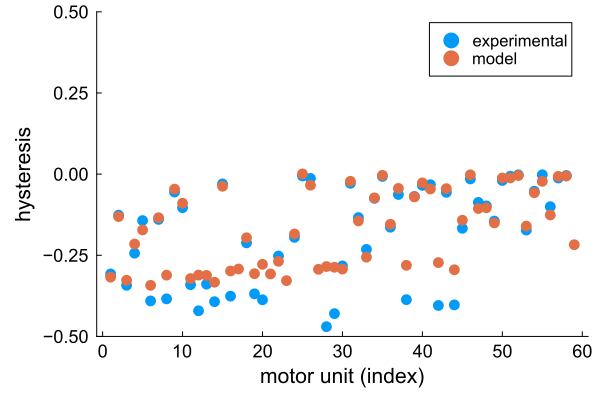

In [31]:
if hysteresis_exp !== nothing
    # Match array sizes
    n_compare = min(length(hysteresis_exp), length(hysteresis[1, :]))

    # Keep only the units that showed hysteresis experimentally (negative values)
    mask = hysteresis_exp[1:n_compare] .< 0
    filtered_exp = hysteresis_exp[1:n_compare][mask]
    filtered_sim = hysteresis[1, 1:n_compare][mask]

    # Remove NaN values from simulation
    valid_mask = .!isnan.(filtered_sim)
    filtered_exp = filtered_exp[valid_mask]
    filtered_sim = filtered_sim[valid_mask]

    if length(filtered_exp) > 0
        # Coefficient of determination R²
        mean_exp = mean(filtered_exp)
        TSS = sum((filtered_exp .- mean_exp).^2)
        RSS = sum((filtered_exp .- filtered_sim).^2)
        R2 = 1 - (RSS / TSS)

        println("\nModel validation:")
        println("  neurons compared: ", length(filtered_exp))
        println("  R² = ", round(R2, digits=3))

        # Experimental and modelled hysteresis, unit by unit
        p = Plots.scatter(filtered_exp, label="experimental", xlabel="motor unit (index)",
                          ylabel="hysteresis", grid=false)
        Plots.scatter!(p, filtered_sim, label="model", ylim=(-0.5, 0.5))
        display(p)
    else
        println("⚠️ No valid neurons for comparison")
    end
else
    println("⚠️ Skipping R² calculation (no experimental data loaded)")
end

---

## 10. Further analyses

### 10.1 Recruitment threshold against maximum firing rate

Units recruited earliest should reach the highest rates — the inverse relationship expected from the size principle.

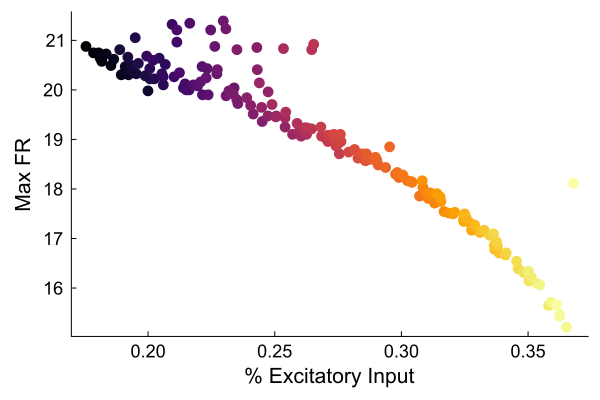

In [32]:
max_vals=zeros(1,nr_s)
color_map = get(ColorSchemes.inferno, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false)

for i in 1:nr_s
    if !isempty(all_rates[i])
        max_vals[1,i]=maximum(all_rates[i])
        Plots.scatter!([recr_inter_input[i]], [max_vals[1,i]],color=color_map[i], grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Max FR")#,ylim=(-0.5, 0.5))
    end
end
display(p)

### 10.2 Units with similar recruitment thresholds

For each motoneuron, find the unit recruited closest to it and compare their calcium thresholds. Two units can recruit at almost the same drive and still carry very different PICs.

In [33]:
mn_that_is_similar = [Int[] for _ in 1:nr_s]

for i in 1:nr_s

    diff = zeros(Float64, nr_s)

    for j in 1:nr_s
        if i==j #do not compare the MN with itself
            diff[j] = NaN
        else
            diff[j] = abs(recr_inter_input[i] - recr_inter_input[j]) #compare recruitment threshold 
        end
    end

    min_diff = minimum(filter(!isnan, diff)) #find the minimum difference between recruitment thresholds of motoneurons 
    
    mn_that_is_similar[i] = findall(x -> x == min_diff, diff)   # find the most similar mn

end
mn_that_is_similar

motoneuron = Int[]
recr_input = Float64[]
similar_motoneuron = Int[]
similar_recr_input = Float64[]
abs_diff = Float64[]

for i in 1:length(recr_inter_input)

    similar_idx = mn_that_is_similar[i][1]  
    diff_value = abs(Vthca_S[i] - Vthca_S[similar_idx])  #compute the diff of VthCa values
    
    push!(motoneuron, i)
    push!(recr_input, recr_inter_input[i])
    push!(similar_motoneuron, similar_idx)
    push!(similar_recr_input, recr_inter_input[similar_idx])
    push!(abs_diff, diff_value)
end

df = DataFrame(Motoneuron = motoneuron, Recr_Input = recr_input, Similar_Motoneuron = similar_motoneuron, Similar_Recr_Input = similar_recr_input, VthCa_Diff = abs_diff)
println(df)



# findmax(df.VthCa_Diff)
# findmin(df.VthCa_Diff)

181×5 DataFrame
 Row │ Motoneuron  Recr_Input  Similar_Motoneuron  Similar_Recr_Input  VthCa_Diff 
     │ Int64       Float64     Int64               Float64             Float64    
─────┼────────────────────────────────────────────────────────────────────────────
   1 │          1    0.175496                   2            0.178471  0.0
   2 │          2    0.178471                   5            0.18048   0.0
   3 │          3    0.181734                   4            0.181109  0.0
   4 │          4    0.181109                   3            0.181734  0.0
   5 │          5    0.18048                    4            0.181109  0.0
   6 │          6    0.185363                  11            0.186446  0.0
   7 │          7    0.182359                   3            0.181734  0.0
   8 │          8    0.189418                  19            0.188821  0.0
   9 │          9    0.183463                   7            0.182359  0.0
  10 │         10    0.190304                  14           

---

## 11. How VthCa and γh shape hysteresis

The pool above uses calcium thresholds that were fitted unit by unit. This section shows where those values come from. It runs a **single** motoneuron while sweeping its calcium activation threshold `VthCa` and its neuromodulation factor `γh`, so you can see how each one moves the hysteresis. Fitting a unit means picking the `VthCa` (at `γh = 1`) whose hysteresis matches the experimental value for that unit.

The sweep uses the same RK4 model as the rest of the notebook, so there is nothing extra to install. Around 30 points takes a minute or two.

In [34]:
# Hysteresis of a single motoneuron, run through the same RK4 model as the full pool
# (run_sim_onemn / ode4), so the sweep stays comparable with Sections 5 and 8.
#
# Returns (hysteresis, recruitment threshold), where hysteresis = DRT/RT - 1, the same
# definition used in Section 8, or (NaN, NaN) if the neuron never fires.

function hysteresis_one_mn(neuron_idx; γh_val=1.0, vthca_val=nothing, inh_level=0.001*0.4)
    MN = MNs[neuron_idx]
    MN[:γh] = γh_val
    vthca_val !== nothing && (MN[:VthCa] = vthca_val)

    # common triangular excitation (ms resolution) + constant inhibition
    amp = 0.4; trl = 28000; hlf = div(trl, 2)
    fl = fill(-0.1, 1000)
    u  = range(-0.1, amp, length=hlf + 1)
    d  = range(amp, -0.1, length=trl - hlf + 1)
    global commoninput = vcat(fl, u[2:end], d[2:end], fl)      # run_sim_onemn reads this global
    inh = fill(inh_level, sim_length)

    # reset this neuron's integrator state, then run the real model
    global pool_state_params[neuron_idx] = (0.0,1.0,0.0,0.0,0.0, 0.0,1.0,0.0,0.0,0.0, -1.0,-1.0,0,0)
    spikes, _ = run_sim_onemn(MN, neuron_idx, inh)

    idx = findall(==(1), spikes[1, :])
    isempty(idx) && return (NaN, NaN)

    # map first/last spike to the excitatory drive at sample resolution (600000 samples)
    h2  = div(560000, 2)
    trs = vcat(fill(-0.1, 20000),
               range(-0.1, amp, length=h2 + 1)[2:end],
               range(amp, -0.1, length=560000 - h2 + 1)[2:end],
               fill(-0.1, 20000))
    rt  = trs[idx[1]]
    drt = trs[idx[end]]
    return (drt / rt - 1, rt)   # ratio hysteresis (same definition as Section 8)
end

println("✓ hysteresis_one_mn defined")

✓ hysteresis_one_mn defined


  VthCa=0.0  ->  hysteresis=0.004
  VthCa=0.5  ->  hysteresis=-0.075
  VthCa=1.0  ->  hysteresis=-0.176
  VthCa=1.5  ->  hysteresis=-0.264
  VthCa=2.0  ->  hysteresis=-0.332
  VthCa=2.5  ->  hysteresis=-0.425
  VthCa=3.0  ->  hysteresis=-0.441
  VthCa=3.5  ->  hysteresis=-0.419
  VthCa=4.0  ->  hysteresis=-0.443

Experimental hysteresis for MN100: 0.118
Best-matching VthCa: 0.0  (model hysteresis 0.004)


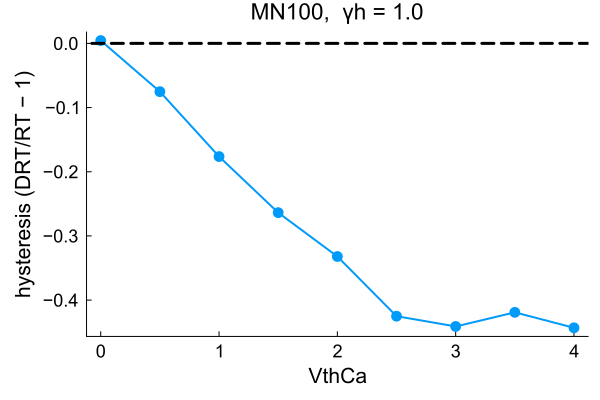

In [35]:
# Sweep VthCa for one motoneuron, with γh held fixed, and watch how hysteresis responds.

neuron_to_optimize = 100
γh_fixed    = 1.0
vthca_range = LinRange(0.0, 4.0, 9)

# keep the originals so this neuron can be put back as it was
γh_orig, vthca_orig = MNs[neuron_to_optimize][:γh], MNs[neuron_to_optimize][:VthCa]

H = fill(NaN, length(vthca_range))
for (k, v) in enumerate(vthca_range)
    H[k], _ = hysteresis_one_mn(neuron_to_optimize; γh_val=γh_fixed, vthca_val=v)
    println("  VthCa=", round(v, digits=2), "  ->  hysteresis=", round(H[k], digits=3))
end

# put this neuron's parameters back
MNs[neuron_to_optimize][:γh]    = γh_orig
MNs[neuron_to_optimize][:VthCa] = vthca_orig

# If experimental data is loaded (Section 9), find the VthCa that best matches it
if @isdefined(hysteresis_exp) && hysteresis_exp !== nothing && neuron_to_optimize <= length(hysteresis_exp)
    target = hysteresis_exp[neuron_to_optimize]
    valid  = .!isnan.(H)
    best_k = findall(valid)[argmin(abs.(H[valid] .- target))]
    println("\nExperimental hysteresis for MN", neuron_to_optimize, ": ", round(target, digits=3))
    println("Best-matching VthCa: ", round(vthca_range[best_k], digits=2),
            "  (model hysteresis ", round(H[best_k], digits=3), ")")
end

# Line: hysteresis vs VthCa (γh fixed)
lp = Plots.plot(collect(vthca_range), H, marker=:circle, lw=2, legend=false, grid=false,
                xlabel="VthCa", ylabel="hysteresis (DRT/RT − 1)",
                title="MN$(neuron_to_optimize),  γh = $(γh_fixed)")
Plots.hline!(lp, [0.0], ls=:dash, color=:black)
display(lp)